# Tutorial — Lab 11: Coreference Resolution & Question Answering

This tutorial **teaches and demonstrates** every concept you need for Lab 11.
Each section has:
* 💡 **Intuition** — the idea in plain words
* 🔬 **Worked Demo** — fully working code that runs and explains itself


In [1]:
# Run this first — installs everything needed for the whole tutorial
!pip install -q fastcoref transformers spacy networkx
!python -m spacy download en_core_web_sm -q
print('All libraries installed ✅')

/data3/chhamman/miniconda3/lib/python3.14/site-packages/torch/cuda/__init__.py:228: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12030). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
All libraries installed ✅


---
# PART A: COREFERENCE RESOLUTION
---

## 1. What is Coreference Resolution?

💡 **Intuition:** The same real-world entity can appear in a text with many different
surface forms. Coreference resolution finds all those *mentions* and groups them into *clusters*.

```
"[Akhila]'s son [Prajwal] was younger than [her] son [Akash].
 [She] resigned herself to make [Akash] the best tree."

Cluster 1 (Akhila): {Akhila, her, She}
Cluster 2 (Akash) : {Akash, Akash}
Cluster 3 (Prajwal): {Prajwal}
```

### Why it matters:
| Application | How coref helps |
|---|---|
| Information Extraction | 'He was born in 1961' — who is *he*? |
| Machine Translation | Hindi 'woh' must become 'he'/'she' depending on the entity |
| Question Answering | Q: 'Who won?' P: 'She scored the most.' → need coref |
| Summarisation | Replacing all pronouns with proper names |

### Two-step process:
1. **Mention Detection** — find all spans that could refer to something
2. **Coreference Clustering** — decide which mentions share an entity

Three types of mentions:
```
Pronouns      → I, she, he, him, they, it
Named Entities → Barack Obama, Paris, IIT Bhilai
Noun Phrases   → 'the tall man', 'her son', 'a red car'
```

## 2. Types of Reference — Coreference vs Anaphora

| Concept | Definition | Example |
|---|---|---|
| **Coreference** | Two mentions refer to the same entity in the world | Barack Obama … Obama … he |
| **Anaphora** | Anaphor's meaning depends on its antecedent | *he* in 'Obama said **he** would sign' |
| **Bridging** | Related but NOT same entity | 'a concert' … 'the tickets' |

**Non-referential NPs — NOT coreference:**
- *'Every dancer twisted her knee'* — *every dancer* is non-specific (no single entity)
- *'It is sunny'* — *it* is expletive, refers to nothing
- *'100 miles'* — a measure, not an entity

⚠️ **Common mistake:** Marking ALL pronouns as mentions. Over-generation is a real problem.
Models typically generate all candidates and then discard singletons at the end.

## 3. Coreference Models: A Brief History

| Model | Key idea | F1 on OntoNotes |
|---|---|---|
| Rule-based (Hobbs, 1978) | Tree-traversal heuristics | ~55 |
| Non-neural ML | Person/number/gender features | ~63 |
| Neural Mention Ranking (Clark & Manning 2016) | Feed-forward NN | 65.4 |
| End-to-end Neural (Lee et al., 2017) | Joint mention detection + clustering | 67.2 |
| **SpanBERT (Joshi et al., 2019)** | **SpanBERT span representations** | **79.6** |

The jump from 67 → 79 F1 came almost entirely from better span representations using SpanBERT.

## 4. Step 1 — Mention Detection (Worked Demo)

💡 **Intuition:** Before we can cluster, we must find all candidate mentions.
We use spaCy to find all three types automatically.

🔬 **Worked Demo — Detecting all three mention types:**

In [2]:
import spacy
nlp = spacy.load('en_core_web_sm')

text = (
    'Barack Obama was born in Hawaii. '
    'He served as the 44th President of the United States. '
    'Obama attended Columbia University. '
    'His presidency lasted from 2009 to 2017.'
)

doc = nlp(text)

print('='*60)
print('TYPE 1: PRONOUNS (via POS tagger)')
print('='*60)
pronouns = [tok for tok in doc if tok.pos_ == 'PRON']
for p in pronouns:
    print(f'  "{p.text}" at position {p.i}  →  {p.tag_} ({p.dep_})')

print()
print('='*60)
print('TYPE 2: NAMED ENTITIES (via NER)')
print('='*60)
for ent in doc.ents:
    print(f'  "{ent.text}"  →  label={ent.label_}  ({spacy.explain(ent.label_)})')

print()
print('='*60)
print('TYPE 3: NOUN PHRASES (via constituency-like noun chunks)')
print('='*60)
for chunk in doc.noun_chunks:
    print(f'  "{chunk.text}"  →  root="{chunk.root.text}" ({chunk.root.dep_})')

/data3/chhamman/miniconda3/lib/python3.14/site-packages/torch/cuda/__init__.py:228: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12030). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


TYPE 1: PRONOUNS (via POS tagger)
  "He" at position 7  →  PRP (nsubj)
  "His" at position 23  →  PRP$ (poss)

TYPE 2: NAMED ENTITIES (via NER)
  "Barack Obama"  →  label=PERSON  (People, including fictional)
  "Hawaii"  →  label=GPE  (Countries, cities, states)
  "44th"  →  label=ORDINAL  ("first", "second", etc.)
  "the United States"  →  label=GPE  (Countries, cities, states)
  "Obama"  →  label=PERSON  (People, including fictional)
  "Columbia University"  →  label=ORG  (Companies, agencies, institutions, etc.)
  "2009"  →  label=DATE  (Absolute or relative dates or periods)

TYPE 3: NOUN PHRASES (via constituency-like noun chunks)
  "Barack Obama"  →  root="Obama" (nsubjpass)
  "Hawaii"  →  root="Hawaii" (pobj)
  "He"  →  root="He" (nsubj)
  "the 44th President"  →  root="President" (pobj)
  "the United States"  →  root="States" (pobj)
  "Obama"  →  root="Obama" (nsubj)
  "Columbia University"  →  root="University" (dobj)
  "His presidency"  →  root="presidency" (nsubj)


🧩 **Try it yourself:**
Change the text to include a sentence like *'It is raining'*.
Do you see 'It' in the pronouns list? What would go wrong if we treated it as a mention?

**Key insight:** All three types together form the set of **candidate mentions**.
The coreference model then decides which ones to keep and which to cluster together.

## 5. Step 2 — Mention-Ranking Model (Worked Demo)

💡 **Intuition:** For each mention, score all candidate antecedents and pick the best.
A dummy antecedent **ε** means 'start a new cluster here'.

The full scoring function:
$$s(i,j) = s_m(i) + s_m(j) + s_a(i,j)$$

- $s_m(i)$: is span $i$ a real mention?
- $s_a(i,j)$: is $i$ a good antecedent for $j$?

🔬 **Worked Demo — Simulating mention-ranking step by step:**

In [3]:
# We simulate mention-ranking with hand-crafted scores
# to show exactly how the algorithm builds clusters.

import numpy as np

# ── Mentions extracted from: 'Obama visited Paris. He loved the city.'
mentions = [
    {'id': 0, 'text': 'Obama'},
    {'id': 1, 'text': 'Paris'},
    {'id': 2, 'text': 'He'},
    {'id': 3, 'text': 'the city'},
]

# ── Simulated antecedent scores: s_a[i][j] = score(mention_i is antecedent of mention_j)
#    Row = antecedent (earlier mention), Col = current mention
#    EPSILON = 'start new cluster' score
EPSILON = 0.0

# scores[j] = dict: antecedent_id → score  (ε means new cluster)
scores = {
    0: {'ε': 1.0},                          # Obama → new cluster (first mention)
    1: {'ε': 1.0},                          # Paris → new cluster
    2: {'ε': -0.5, 0: 1.2, 1: -0.3},       # He: Obama=1.2 (best!), Paris=-0.3
    3: {'ε': -0.2, 0: 0.1, 1: 0.9, 2: 0.2} # 'the city': Paris=0.9 (best!)
}

# ── Build clusters by following best antecedents
antecedent_of = {}  # mention_id → antecedent_id (or 'ε')

print('MENTION-RANKING STEP BY STEP')
print('='*55)
for j, m in enumerate(mentions):
    best_ant = max(scores[j], key=lambda k: scores[j][k])
    antecedent_of[j] = best_ant
    print(f'Mention [{j}] "{m["text"]}"')
    for ant, sc in scores[j].items():
        marker = ' ← BEST' if ant == best_ant else ''
        label = f'ε (new cluster)' if ant == 'ε' else f'[{ant}] "{mentions[ant]["text"]}"'
        print(f'   score({label}) = {sc:+.1f}{marker}')
    print()

# ── Trace clusters
print('CLUSTER BUILDING')
print('='*55)
from collections import defaultdict
# Union-Find to merge clusters
parent = list(range(len(mentions)))

def find(x):
    while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
    return x

def union(a, b):
    parent[find(a)] = find(b)

for j in range(len(mentions)):
    ant = antecedent_of[j]
    if ant != 'ε':
        union(j, ant)
        print(f'  Linking [{j}] "{mentions[j]["text"]}" → [{ant}] "{mentions[ant]["text"]}"')
    else:
        print(f'  [{j}] "{mentions[j]["text"]}" → starts NEW cluster')

# Group into clusters
clusters = defaultdict(list)
for j in range(len(mentions)):
    clusters[find(j)].append(mentions[j]['text'])

print()
print('FINAL COREFERENCE CLUSTERS')
print('='*55)
for i, (root, members) in enumerate(clusters.items(), 1):
    print(f'  Cluster {i}: {members}')

MENTION-RANKING STEP BY STEP
Mention [0] "Obama"
   score(ε (new cluster)) = +1.0 ← BEST

Mention [1] "Paris"
   score(ε (new cluster)) = +1.0 ← BEST

Mention [2] "He"
   score(ε (new cluster)) = -0.5
   score([0] "Obama") = +1.2 ← BEST
   score([1] "Paris") = -0.3

Mention [3] "the city"
   score(ε (new cluster)) = -0.2
   score([0] "Obama") = +0.1
   score([1] "Paris") = +0.9 ← BEST
   score([2] "He") = +0.2

CLUSTER BUILDING
  [0] "Obama" → starts NEW cluster
  [1] "Paris" → starts NEW cluster
  Linking [2] "He" → [0] "Obama"
  Linking [3] "the city" → [1] "Paris"

FINAL COREFERENCE CLUSTERS
  Cluster 1: ['Obama', 'He']
  Cluster 2: ['Paris', 'the city']


🧩 **Try it yourself:**
Change the scores so that 'He' gets linked to 'Paris' instead of 'Obama'.
What cluster structure do you get? Is it correct?

**Key insight:** The mention-ranking model learns these scores from annotated training data.
SpanBERT gives much better features for computing $s_m$ and $s_a$.

## 6. SpanBERT — How it Represents Spans

💡 **Intuition:** SpanBERT was pre-trained with a special objective:
predict the content of a *span* using only its **boundary tokens**.
This forces the model to create rich span representations.

For a span from token $i$ to token $j$, SpanBERT computes:
$$g(i,j) = [\mathbf{h}_i,\ \mathbf{h}_j,\ \tilde{\mathbf{h}}(i,j),\ \phi(i,j)]$$

| Component | Meaning |
|---|---|
| $\mathbf{h}_i$ | BERT embedding of the **first** token of the span |
| $\mathbf{h}_j$ | BERT embedding of the **last** token of the span |
| $\tilde{\mathbf{h}}(i,j)$ | Attention-weighted **head** of the span |
| $\phi(i,j)$ | Span **features**: length, etc. |

🔬 **Worked Demo — Computing a span representation from BERT embeddings:**

In [4]:
import torch
from transformers import AutoTokenizer, AutoModel

# Use a small BERT model (distilbert) to keep it fast for demo
model_name = 'distilbert-base-uncased'
tokenizer  = AutoTokenizer.from_pretrained(model_name)
bert       = AutoModel.from_pretrained(model_name)
bert.eval()

sentence = 'Barack Obama attended Columbia University.'
inputs   = tokenizer(sentence, return_tensors='pt')
tokens   = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

with torch.no_grad():
    hidden = bert(**inputs).last_hidden_state[0]  # [seq_len, 768]

print(f'Sentence   : {sentence}')
print(f'Tokens     : {tokens}')
print(f'Hidden size: {hidden.shape}  (seq_len x embedding_dim)\n')

# ── Compute span representation for 'Barack Obama' (tokens 1–2)
span_name = 'Barack Obama'
i, j = 1, 2  # token indices in the tokenized sequence

h_i = hidden[i]   # first token embedding
h_j = hidden[j]   # last token embedding

# Attention-weighted head: uniform attention for this demo
span_tokens = hidden[i:j+1]             # shape: [span_len, 768]
attn_weights = torch.softmax(torch.ones(j-i+1), dim=0)  # uniform
h_head = (attn_weights.unsqueeze(1) * span_tokens).sum(dim=0)

# Span features: just the length here
span_length = torch.tensor([j - i + 1], dtype=torch.float)

# Full span representation
g = torch.cat([h_i, h_j, h_head, span_length])

print(f'Span: "{span_name}"  (tokens {i}–{j})')
print(f'  h_i  shape: {h_i.shape}     (first token)')
print(f'  h_j  shape: {h_j.shape}     (last  token)')
print(f'  h̃   shape: {h_head.shape}  (attention head)')
print(f'  φ    value: {span_length.item()} (span length)')
print(f'  g    shape: {g.shape}   (full span repr: 768+768+768+1)')

/data3/chhamman/miniconda3/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 9278.20it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Sentence   : Barack Obama attended Columbia University.
Tokens     : ['[CLS]', 'barack', 'obama', 'attended', 'columbia', 'university', '.', '[SEP]']
Hidden size: torch.Size([8, 768])  (seq_len x embedding_dim)

Span: "Barack Obama"  (tokens 1–2)
  h_i  shape: torch.Size([768])     (first token)
  h_j  shape: torch.Size([768])     (last  token)
  h̃   shape: torch.Size([768])  (attention head)
  φ    value: 2.0 (span length)
  g    shape: torch.Size([2305])   (full span repr: 768+768+768+1)


## 7. Full SpanBERT Coreference Pipeline (End-to-End Demo)

Now we combine everything: mention detection + mention ranking + clustering,
all done inside a pre-trained SpanBERT model via `fastcoref`.

🔬 **Worked Demo — Running the full pipeline and inspecting every step:**

In [5]:
from fastcoref import FCoref

# ── Compatibility fix: fastcoref 2.1.6 was written for transformers 4.x.
#    transformers 5.x expects models to call post_init() (which sets
#    `all_tied_weights_keys`); FCorefModel doesn't, so we call it here.
import fastcoref.modeling as _fc_modeling
if not getattr(_fc_modeling.FCorefModel, '_patched_post_init', False):
    _orig_init = _fc_modeling.FCorefModel.__init__
    def _patched_init(self, *args, **kwargs):
        _orig_init(self, *args, **kwargs)
        if not hasattr(self, 'all_tied_weights_keys'):
            self.post_init()
    _fc_modeling.FCorefModel.__init__ = _patched_init
    _fc_modeling.FCorefModel._patched_post_init = True

coref_model = FCoref(device='cpu')

# ── Example 1: Basic pronoun resolution
text1 = 'Akhila met Prajwal at the park. She waved at him. He smiled back at her.'
pred1 = coref_model.predict(texts=[text1])[0]

print('Example 1:', text1)
print('─'*60)
print('CLUSTERS (as strings):')
for cluster in pred1.get_clusters(as_strings=True):
    print(f'  {cluster}')

print('\nCLUSTERS (with character offsets):')
for cluster in pred1.get_clusters(as_strings=False):
    spans = [f'"{text1[s:e]}" [{s}:{e}]' for s, e in cluster]
    print(f'  {spans}')

10/15/2026 16:43:56 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/biu-nlp/f-coref "HTTP/1.1 200 OK"
10/15/2026 16:43:57 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/biu-nlp/f-coref "HTTP/1.1 200 OK"
10/15/2026 16:43:57 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/biu-nlp/f-coref/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
10/15/2026 16:43:57 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/biu-nlp/f-coref/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
10/15/2026 16:43:58 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/biu-nlp/f-coref/revision/main "HTTP/1.1 200 OK"
10/15/2026 16:43:58 - INFO - 	 HTTP Request: HEAD https://huggingface.co/biu-nlp/f-coref/resolve/main/model.safetensors "HTTP/1.1 404 Not Found"
10/15/2026 16:43:58 - WARNING - 	 Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate lim

Example 1: Akhila met Prajwal at the park. She waved at him. He smiled back at her.
────────────────────────────────────────────────────────────
CLUSTERS (as strings):
  ['Akhila', 'She', 'her']
  ['Prajwal', 'him', 'He']

CLUSTERS (with character offsets):
  ['"Akhila" [0:6]', '"She" [32:35]', '"her" [68:71]']
  ['"Prajwal" [11:18]', '"him" [45:48]', '"He" [50:52]']


In [6]:
# ── Example 2: Multi-sentence with named entities
text2 = (
    'Barack Obama was born in Hawaii. '
    'He served as the 44th President of the United States. '
    'Obama attended Columbia University. '
    'His presidency lasted from 2009 to 2017.'
)
pred2 = coref_model.predict(texts=[text2])[0]

print('Example 2:', text2)
print('─'*60)
print('CLUSTERS (as strings):')
for cluster in pred2.get_clusters(as_strings=True):
    print(f'  {cluster}')

print()
print('WHAT THE MODEL DID:')
print('  Step 1: Detected all mentions (pronouns, NEs, NPs)')
print('  Step 2: Scored every (mention, antecedent) pair')
print('  Step 3: Linked each mention to its best antecedent')
print('  Step 4: Discarded singleton mentions')

10/15/2026 16:43:59 - INFO - 	 Tokenize 1 inputs...
10/15/2026 16:43:59 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/biu-nlp/f-coref/commits/main "HTTP/1.1 200 OK"
10/15/2026 16:43:59 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/biu-nlp/f-coref/discussions?p=0 "HTTP/1.1 200 OK"
Map: 100%|██████████| 1/1 [00:00<00:00, 131.95 examples/s]
10/15/2026 16:43:59 - INFO - 	 ***** Running Inference on 1 texts *****
Inference: 100%|██████████| 1/1 [00:00<00:00, 51.90it/s]

Example 2: Barack Obama was born in Hawaii. He served as the 44th President of the United States. Obama attended Columbia University. His presidency lasted from 2009 to 2017.
────────────────────────────────────────────────────────────
CLUSTERS (as strings):
  ['Barack Obama', 'He', 'Obama', 'His']

WHAT THE MODEL DID:
  Step 1: Detected all mentions (pronouns, NEs, NPs)
  Step 2: Scored every (mention, antecedent) pair
  Step 3: Linked each mention to its best antecedent
  Step 4: Discarded singleton mentions


In [7]:
# ── Example 3: Where the model can fail
# Two female characters — same gender, model must rely on semantics not just gender
text3 = (
    'Maria is a doctor. Priya is an engineer. '
    'She works at the city hospital. '
    'She designed the new bridge.'
)
pred3 = coref_model.predict(texts=[text3])[0]

print('Example 3 (ambiguous):', text3)
print('─'*60)
print('CLUSTERS:')
for cluster in pred3.get_clusters(as_strings=True):
    print(f'  {cluster}')

print()
print('Expected:')
print('  Cluster 1: {Maria, She (hospital)}   — doctor → hospital')
print('  Cluster 2: {Priya, She (bridge)}     — engineer → bridge')
print()
print('Does the model get it right? This requires WORLD KNOWLEDGE, not just syntax!')

10/15/2026 16:43:59 - INFO - 	 Tokenize 1 inputs...
10/15/2026 16:43:59 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/biu-nlp/f-coref/commits/refs%2Fpr%2F1 "HTTP/1.1 200 OK"
Map: 100%|██████████| 1/1 [00:00<00:00, 144.49 examples/s]
10/15/2026 16:44:00 - INFO - 	 ***** Running Inference on 1 texts *****
Inference: 100%|██████████| 1/1 [00:00<00:00, 50.61it/s]

Example 3 (ambiguous): Maria is a doctor. Priya is an engineer. She works at the city hospital. She designed the new bridge.
────────────────────────────────────────────────────────────
CLUSTERS:
  ['Priya', 'She', 'She']

Expected:
  Cluster 1: {Maria, She (hospital)}   — doctor → hospital
  Cluster 2: {Priya, She (bridge)}     — engineer → bridge

Does the model get it right? This requires WORLD KNOWLEDGE, not just syntax!


## 8. B-cubed Evaluation (Worked Demo)

💡 **Intuition:** For each mention, how many of your predicted cluster members are correct (Precision)
and how many of the gold cluster members did you find (Recall)?

$$P_m = \frac{|C_{gold}(m) \cap C_{sys}(m)|}{|C_{sys}(m)|} \qquad R_m = \frac{|C_{gold}(m) \cap C_{sys}(m)|}{|C_{gold}(m)|}$$

🔬 **Worked Demo — step by step:**

In [8]:
def bcubed_verbose(gold_clusters, system_clusters):
    """
    Compute B-cubed with full step-by-step printing.
    """
    gold_map   = {m: i for i, c in enumerate(gold_clusters)   for m in c}
    system_map = {m: i for i, c in enumerate(system_clusters) for m in c}
    all_mentions = set(gold_map) & set(system_map)

    print(f'{'Mention':<12} {'Gold Cluster':<28} {'Sys Cluster':<28} {'P_m':>5} {'R_m':>5}')
    print('─'*80)

    p_total = r_total = 0.0
    for m in sorted(all_mentions):
        gc = gold_clusters[gold_map[m]]
        sc = system_clusters[system_map[m]]
        ov = len(gc & sc)
        pm = ov / len(sc)
        rm = ov / len(gc)
        p_total += pm; r_total += rm
        print(f'{m:<12} {str(sorted(gc)):<28} {str(sorted(sc)):<28} {pm:>5.2f} {rm:>5.2f}')

    n = len(all_mentions)
    P = p_total / n; R = r_total / n
    F1 = 2*P*R/(P+R) if (P+R) > 0 else 0
    print('─'*80)
    print(f'Average P = {P:.3f}   Average R = {R:.3f}   F1 = {F1:.3f}')
    return P, R, F1

# Case 1: Imperfect system
gold   = [{'A','B','C','D'}, {'E','F','G'}]
system = [{'A','B','C','E'}, {'D','F','G'}]

print('=== CASE 1: System makes errors ===')
bcubed_verbose(gold, system)

print()
print('=== CASE 2: Perfect system ===')
bcubed_verbose(gold, gold)

=== CASE 1: System makes errors ===
Mention      Gold Cluster                 Sys Cluster                    P_m   R_m
────────────────────────────────────────────────────────────────────────────────
A            ['A', 'B', 'C', 'D']         ['A', 'B', 'C', 'E']          0.75  0.75
B            ['A', 'B', 'C', 'D']         ['A', 'B', 'C', 'E']          0.75  0.75
C            ['A', 'B', 'C', 'D']         ['A', 'B', 'C', 'E']          0.75  0.75
D            ['A', 'B', 'C', 'D']         ['D', 'F', 'G']               0.33  0.25
E            ['E', 'F', 'G']              ['A', 'B', 'C', 'E']          0.25  0.33
F            ['E', 'F', 'G']              ['D', 'F', 'G']               0.67  0.67
G            ['E', 'F', 'G']              ['D', 'F', 'G']               0.67  0.67
────────────────────────────────────────────────────────────────────────────────
Average P = 0.595   Average R = 0.595   F1 = 0.595

=== CASE 2: Perfect system ===
Mention      Gold Cluster                 Sys Cluster  

(1.0, 1.0, 1.0)

---
# PART B: QUESTION ANSWERING
---

## 9. Types of Question Answering

💡 **Intuition:** QA systems answer natural language questions automatically.
There are three major paradigms — each with different data sources and methods:

```
┌─────────────────────────────────────────────────────────┐
│  QUESTION ANSWERING TAXONOMY                            │
│                                                         │
│  1. Reading Comprehension (RC-QA)                       │
│     Input: (passage, question) → span answer            │
│     Dataset: SQuAD, TriviaQA                           │
│     Model: BERT fine-tuned for span extraction          │
│                                                         │
│  2. Open-Domain QA                                      │
│     Input: question → answer from large corpus         │
│     Dataset: Natural Questions, TriviaQA               │
│     Model: Retriever (BM25/DPR) + Reader (BERT)        │
│                                                         │
│  3. Knowledge Graph QA (KG-QA)  ← NEW in this lab      │
│     Input: question → answer from structured KB        │
│     Dataset: WebQuestions, FreebaseQA                  │
│     Model: Entity linking + SPARQL / GNN               │
└─────────────────────────────────────────────────────────┘
```

We will demonstrate **all three** in this tutorial.

## 10. RC-QA — BERT for SQuAD (Worked Demo)

💡 **Intuition:** Fine-tune BERT with two linear classifiers on top:
one predicts the **start** of the answer span, one predicts the **end**.

```
Input:  [CLS] question tokens [SEP] passage tokens [SEP]
Output: start_logits[i] + end_logits[i]  for every passage token

Answer = passage[ argmax(start) : argmax(end) + 1 ]
         with constraint: end >= start
```

🔬 **Worked Demo — BERT QA with step-by-step explanation:**

In [9]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForQuestionAnswering

qa_model_name = 'deepset/bert-base-cased-squad2'
qa_tokenizer  = AutoTokenizer.from_pretrained(qa_model_name)
qa_model      = AutoModelForQuestionAnswering.from_pretrained(qa_model_name)
qa_model.eval()
print('BERT QA model loaded ✅')

10/15/2026 16:44:00 - INFO - 	 HTTP Request: HEAD https://huggingface.co/biu-nlp/f-coref/resolve/refs%2Fpr%2F1/model.safetensors.index.json "HTTP/1.1 404 Not Found"
10/15/2026 16:44:00 - INFO - 	 HTTP Request: HEAD https://huggingface.co/biu-nlp/f-coref/resolve/refs%2Fpr%2F1/model.safetensors "HTTP/1.1 302 Found"
10/15/2026 16:44:00 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/deepset/bert-base-cased-squad2 "HTTP/1.1 200 OK"
10/15/2026 16:44:01 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/deepset/bert-base-cased-squad2/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
10/15/2026 16:44:01 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/deepset/bert-base-cased-squad2/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
10/15/2026 16:44:01 - INFO - 	 HTTP Request: GET https://huggingface.co/api/models/deepset/bert-base-cased-squad2 "HTTP/1.1 200 OK"
Loading weights: 100%|██████████| 199/199 [00:0

BERT QA model loaded ✅


In [10]:
def bert_qa_demo(question, context, verbose=True):
    """
    Full BERT QA with step-by-step output.
    Returns: answer string, score
    """
    # ── Step 1: Tokenise
    inputs = qa_tokenizer(question, context, return_tensors='pt',
                          truncation=True, max_length=512)
    tokens = qa_tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

    # Find where context starts (after second [SEP])
    sep_positions = (inputs['input_ids'][0] == qa_tokenizer.sep_token_id).nonzero().squeeze().tolist()
    context_start = sep_positions[0] + 1  # tokens after first [SEP]

    if verbose:
        print('STEP 1 — TOKENISATION')
        print(f'  Question tokens : {tokens[1:sep_positions[0]]}')
        print(f'  Context tokens  : {tokens[context_start:sep_positions[1]]}')

    # ── Step 2: Forward pass
    with torch.no_grad():
        outputs = qa_model(**inputs)
    start_logits = outputs.start_logits[0]
    end_logits   = outputs.end_logits[0]

    # ── Step 3: Mask question tokens, find best span
    start_logits[:context_start] = float('-inf')
    end_logits[:context_start]   = float('-inf')

    best_score = float('-inf')
    best_s, best_e = context_start, context_start
    n = len(tokens)
    for s in range(context_start, n):
        for e in range(s, min(s+30, n)):
            sc = start_logits[s].item() + end_logits[e].item()
            if sc > best_score:
                best_score = sc; best_s = s; best_e = e

    answer = qa_tokenizer.convert_tokens_to_string(tokens[best_s:best_e+1]).strip()

    if verbose:
        print()
        print('STEP 2 — BERT PRODUCES LOGITS')
        print(f'  Top 3 start candidates:')
        top_starts = torch.topk(start_logits[context_start:], 3)
        for score, idx in zip(top_starts.values, top_starts.indices):
            print(f'    "{tokens[context_start + idx.item()]}"  score={score.item():.2f}')
        print(f'  Top 3 end candidates:')
        top_ends = torch.topk(end_logits[context_start:], 3)
        for score, idx in zip(top_ends.values, top_ends.indices):
            print(f'    "{tokens[context_start + idx.item()]}"  score={score.item():.2f}')
        print()
        print('STEP 3 — BEST VALID SPAN (end >= start)')
        print(f'  start token [{best_s}]: "{tokens[best_s]}"')
        print(f'  end   token [{best_e}]: "{tokens[best_e]}"')
        print(f'  ANSWER: "{answer}"  (span score={best_score:.2f})')

    return answer, best_score, tokens, start_logits, end_logits, context_start

# ── Run a demo
question = 'What did Tesla study at Primary School?'
context  = ('In 1861, Tesla attended the Primary School in Smiljan '
             'where he studied German, arithmetic, and religion. '
             'In 1862, the Tesla family moved to Gospic.')
print('Q:', question)
print('C:', context)
print('='*60)
answer, score, tokens, sl, el, ctx_start = bert_qa_demo(question, context)

Q: What did Tesla study at Primary School?
C: In 1861, Tesla attended the Primary School in Smiljan where he studied German, arithmetic, and religion. In 1862, the Tesla family moved to Gospic.
STEP 1 — TOKENISATION
  Question tokens : ['What', 'did', 'Te', '##sla', 'study', 'at', 'Primary', 'School', '?']
  Context tokens  : ['In', '1861', ',', 'Te', '##sla', 'attended', 'the', 'Primary', 'School', 'in', 'S', '##mi', '##l', '##jan', 'where', 'he', 'studied', 'German', ',', 'arithmetic', ',', 'and', 'religion', '.', 'In', '1862', ',', 'the', 'Te', '##sla', 'family', 'moved', 'to', 'Go', '##sp', '##ic', '.']

STEP 2 — BERT PRODUCES LOGITS
  Top 3 start candidates:
    "German"  score=4.47
    "arithmetic"  score=1.07
    "he"  score=-0.16
  Top 3 end candidates:
    "religion"  score=4.65
    "German"  score=3.35
    "."  score=1.99

STEP 3 — BEST VALID SPAN (end >= start)
  start token [28]: "German"
  end   token [33]: "religion"
  ANSWER: "German, arithmetic, and religion"  (span sco

/data3/chhamman/miniconda3/lib/python3.14/site-packages/matplotlib/transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),
/data3/chhamman/miniconda3/lib/python3.14/site-packages/matplotlib/transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),
/data3/chhamman/miniconda3/lib/python3.14/site-packages/matplotlib/transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


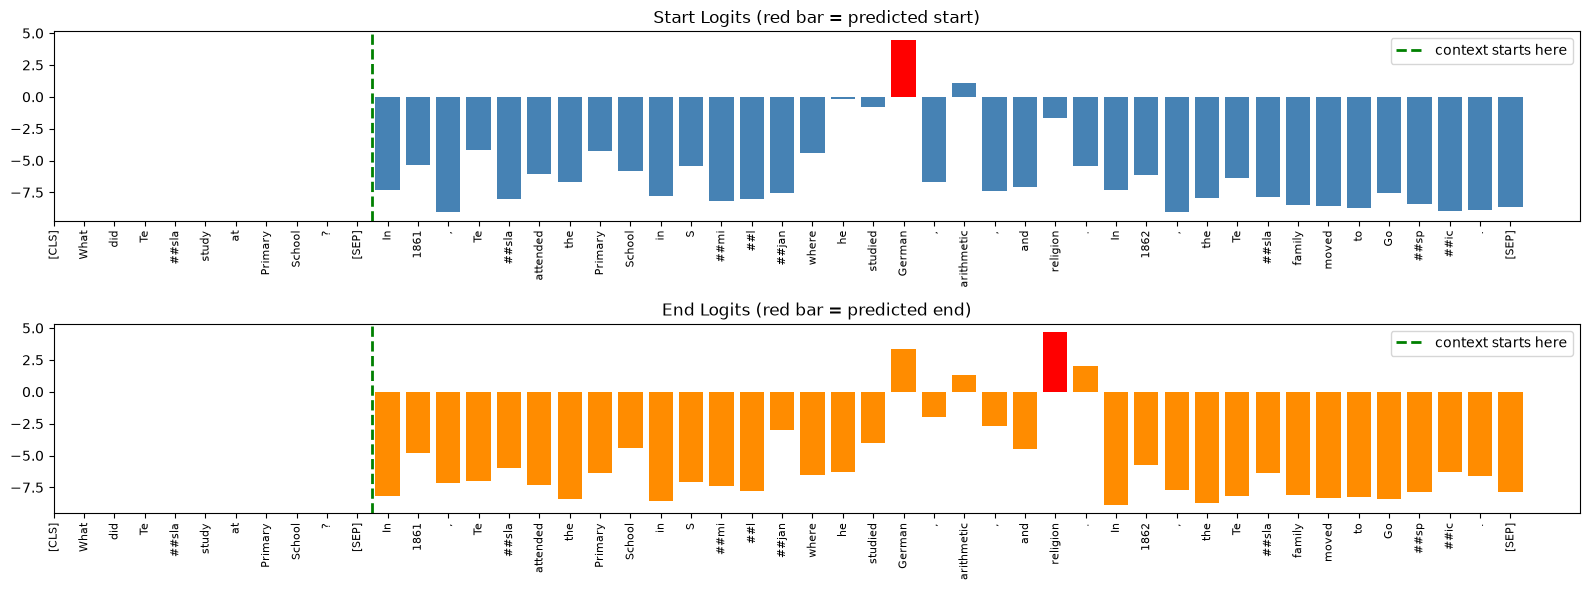

Notice: logits for question tokens (left of green line) are masked to -inf


In [11]:
# ── Visualise the logits
x = np.arange(len(tokens))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 6))

colors_s = ['red' if i == torch.argmax(sl).item() else 'steelblue' for i in range(len(tokens))]
colors_e = ['red' if i == torch.argmax(el).item() else 'darkorange' for i in range(len(tokens))]

ax1.bar(x, sl.numpy(), color=colors_s)
ax1.set_xticks(x); ax1.set_xticklabels(tokens, rotation=90, fontsize=8)
ax1.set_title('Start Logits (red bar = predicted start)')
ax1.axvline(ctx_start - 0.5, color='green', lw=2, linestyle='--', label='context starts here')
ax1.legend()

ax2.bar(x, el.numpy(), color=colors_e)
ax2.set_xticks(x); ax2.set_xticklabels(tokens, rotation=90, fontsize=8)
ax2.set_title('End Logits (red bar = predicted end)')
ax2.axvline(ctx_start - 0.5, color='green', lw=2, linestyle='--', label='context starts here')
ax2.legend()

plt.tight_layout(); plt.show()
print('Notice: logits for question tokens (left of green line) are masked to -inf')

In [12]:
# ── SQuAD v2.0: Unanswerable question
print('=== SQuAD v2.0: Unanswerable Question ===')
print()
q_unans  = 'What year was Tesla born?'
ctx_unans = 'Tesla studied German and arithmetic at Primary School in Smiljan.'
print('Q:', q_unans)
print('C:', ctx_unans)
print('─'*60)
ans, sc, *_ = bert_qa_demo(q_unans, ctx_unans, verbose=False)
print(f'Predicted: "{ans}"  score={sc:.2f}')
print()
print('SQuAD v2.0 approach: compute CLS score = start_logit[CLS] + end_logit[CLS]')
print('If CLS score > span score → predict NO ANSWER')

inputs_u = qa_tokenizer(q_unans, ctx_unans, return_tensors='pt')
with torch.no_grad():
    out_u = qa_model(**inputs_u)
cls_score = out_u.start_logits[0][0].item() + out_u.end_logits[0][0].item()
print(f'CLS score (no-answer) = {cls_score:.2f}')
print(f'Span score            = {sc:.2f}')
print(f'Decision: {"NO ANSWER" if cls_score > sc else "ANSWER EXISTS"}')

=== SQuAD v2.0: Unanswerable Question ===

Q: What year was Tesla born?
C: Tesla studied German and arithmetic at Primary School in Smiljan.
────────────────────────────────────────────────────────────
Predicted: "German and arithmetic at Primary School in Smiljan."  score=-5.35

SQuAD v2.0 approach: compute CLS score = start_logit[CLS] + end_logit[CLS]
If CLS score > span score → predict NO ANSWER
CLS score (no-answer) = 3.85
Span score            = -5.35
Decision: NO ANSWER


## 11. Open-Domain QA — Retriever + Reader (Worked Demo)

💡 **Intuition:** When there is no given passage, the system must first FIND
relevant documents from a large corpus, then EXTRACT the answer.

```
Question
    ↓
[RETRIEVER]  ←── BM25 (keyword match) or DPR (dense vectors)
    ↓              Top-k passages from Wikipedia
[READER]     ←── BERT extracts span from each passage
    ↓
Answer with highest confidence
```

🔬 **Worked Demo — TF-IDF Retriever + BERT Reader:**

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Mini knowledge corpus
CORPUS = [
    'Barack Obama was born in Hawaii and served as the 44th US President from 2009 to 2017.',
    'Nikola Tesla was a Serbian-American inventor known for his work on alternating current.',
    'Marie Curie discovered polonium and radium and was the first woman to win the Nobel Prize.',
    'The Eiffel Tower is located in Paris and was constructed between 1887 and 1889.',
    'Albert Einstein developed the theory of relativity and won the 1921 Nobel Prize in Physics.',
    'The Amazon rainforest produces 20 percent of the worlds oxygen and spans 9 countries.',
    'Mahatma Gandhi led India to independence using nonviolent civil disobedience.',
    'Python programming language was created by Guido van Rossum and released in 1991.',
]

def tfidf_retrieve(query, corpus, k=3):
    """Return top-k passages most similar to query using TF-IDF cosine similarity."""
    vect = TfidfVectorizer()
    doc_vecs = vect.fit_transform(corpus)
    q_vec    = vect.transform([query])
    sims     = cosine_similarity(q_vec, doc_vecs).flatten()
    top_k    = np.argsort(sims)[::-1][:k]
    return [(float(sims[i]), corpus[i]) for i in top_k]

def open_domain_qa(question, corpus, k=3):
    """Retrieve top-k passages, run BERT reader on each, return best answer."""
    retrieved = tfidf_retrieve(question, corpus, k=k)
    best_answer, best_score = '', float('-inf')
    print(f'Question: {question}')
    print('─'*60)
    print('Retrieved passages:')
    for rank, (ret_score, passage) in enumerate(retrieved, 1):
        ans, qa_score, *_ = bert_qa_demo(question, passage, verbose=False)
        print(f'  [{rank}] retrieval_sim={ret_score:.3f}  qa_score={qa_score:.2f}')
        print(f'      passage: "{passage[:70]}..."')
        print(f'      extracted answer: "{ans}"')
        if qa_score > best_score:
            best_score = qa_score; best_answer = ans
    print()
    print(f'✅ FINAL ANSWER: "{best_answer}" (score={best_score:.2f})')
    return best_answer

_ = open_domain_qa('Where was Barack Obama born?', CORPUS)

Question: Where was Barack Obama born?
────────────────────────────────────────────────────────────
Retrieved passages:
  [1] retrieval_sim=0.490  qa_score=15.28
      passage: "Barack Obama was born in Hawaii and served as the 44th US President fr..."
      extracted answer: "Hawaii"
  [2] retrieval_sim=0.052  qa_score=-10.31
      passage: "Python programming language was created by Guido van Rossum and releas..."
      extracted answer: "1991"
  [3] retrieval_sim=0.052  qa_score=-10.95
      passage: "The Eiffel Tower is located in Paris and was constructed between 1887 ..."
      extracted answer: "1889"

✅ FINAL ANSWER: "Hawaii" (score=15.28)


In [14]:
print()
_ = open_domain_qa('Who won the Nobel Prize for discovering radium?', CORPUS)


Question: Who won the Nobel Prize for discovering radium?
────────────────────────────────────────────────────────────
Retrieved passages:
  [1] retrieval_sim=0.403  qa_score=-3.23
      passage: "Albert Einstein developed the theory of relativity and won the 1921 No..."
      extracted answer: "1921 Nobel Prize in Physics"
  [2] retrieval_sim=0.395  qa_score=2.75
      passage: "Marie Curie discovered polonium and radium and was the first woman to ..."
      extracted answer: "woman"
  [3] retrieval_sim=0.131  qa_score=-3.54
      passage: "Nikola Tesla was a Serbian-American inventor known for his work on alt..."
      extracted answer: "Nikola Tesla"

✅ FINAL ANSWER: "woman" (score=2.75)


## 12. Knowledge Graph QA — KG-QA (Worked Demo)

💡 **Intuition:** Instead of searching unstructured text, KG-QA answers questions
from a **structured knowledge graph** — a network of (entity, relation, entity) triples.

```
Knowledge Graph triples:
  (Barack Obama, born_in,    Hawaii)
  (Barack Obama, role,       President)
  (Marie Curie,  discovered, Radium)
  (Marie Curie,  won,        Nobel Prize)
  (Radium,       discovered_by, Marie Curie)

Question: 'What did Marie Curie discover?'
→ Entity Linking: 'Marie Curie' → Marie_Curie node
→ Relation Detection: 'discover' → discovered relation
→ Graph Traversal: Marie_Curie --discovered--> Radium, Polonium
→ Answer: 'Radium, Polonium'
```

**Two steps:**
1. **Entity Linking** — map question words to KG entities
2. **Relation Detection** — identify which relation to traverse

🔬 **Worked Demo — Building a mini KG and answering questions over it:**

Knowledge Graph: 19 nodes, 16 edges
Entities: ['Barack Obama', 'Hawaii', 'President', 'Columbia University', 'Harvard Law School', 'American', 'Marie Curie', 'Radium', 'Polonium', 'Nobel Prize in Physics', 'Nobel Prize in Chemistry', 'Polish-French', 'Nikola Tesla', 'AC Motor', 'Serbia', 'Thomas Edison', 'Albert Einstein', 'Theory of Relativity', 'Germany']


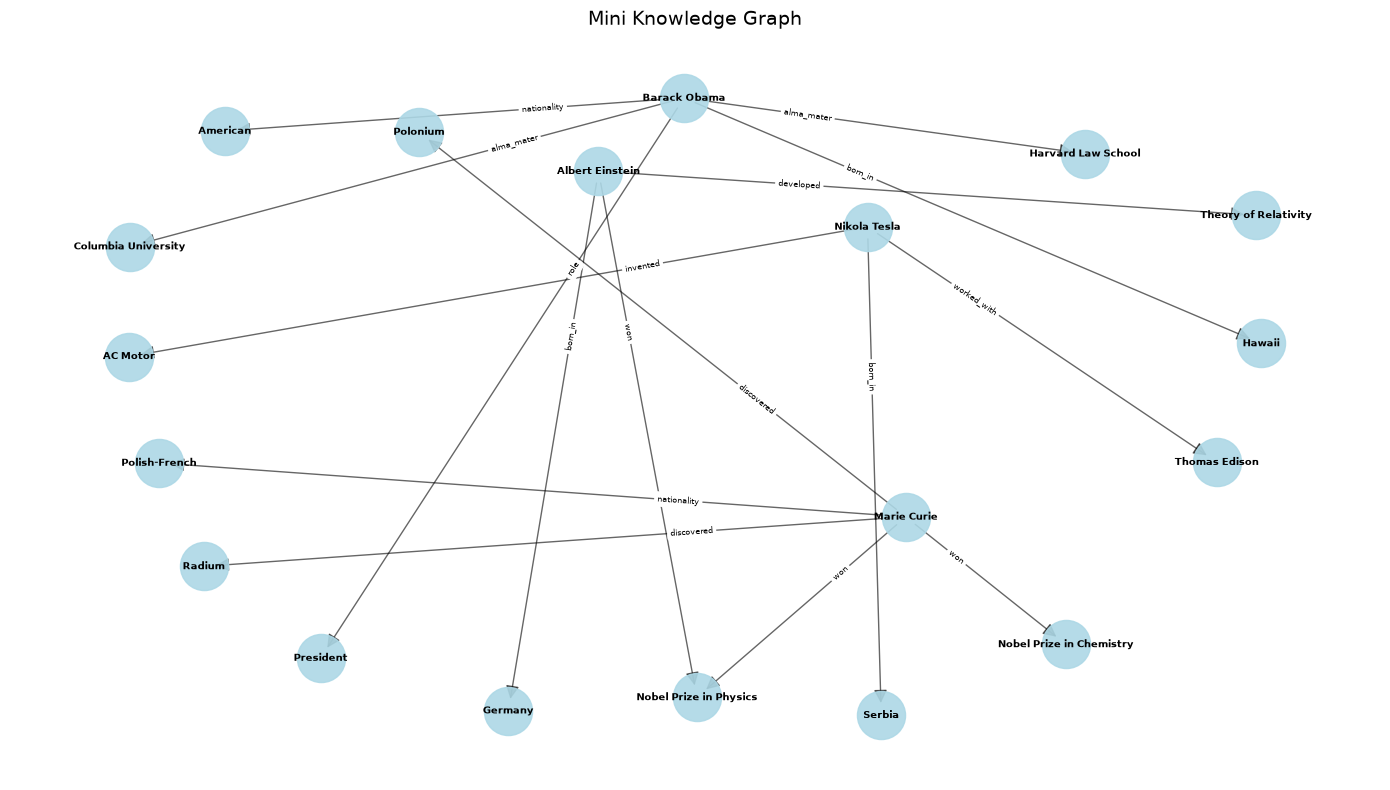

In [15]:
import networkx as nx
import matplotlib.pyplot as plt
import re

# ── Build a mini Knowledge Graph
KG_TRIPLES = [
    ('Barack Obama',  'born_in',      'Hawaii'),
    ('Barack Obama',  'role',         'President'),
    ('Barack Obama',  'alma_mater',   'Columbia University'),
    ('Barack Obama',  'alma_mater',   'Harvard Law School'),
    ('Barack Obama',  'nationality',  'American'),
    ('Marie Curie',   'discovered',   'Radium'),
    ('Marie Curie',   'discovered',   'Polonium'),
    ('Marie Curie',   'won',          'Nobel Prize in Physics'),
    ('Marie Curie',   'won',          'Nobel Prize in Chemistry'),
    ('Marie Curie',   'nationality',  'Polish-French'),
    ('Nikola Tesla',  'invented',     'AC Motor'),
    ('Nikola Tesla',  'born_in',      'Serbia'),
    ('Nikola Tesla',  'worked_with',  'Thomas Edison'),
    ('Albert Einstein','developed',   'Theory of Relativity'),
    ('Albert Einstein','won',         'Nobel Prize in Physics'),
    ('Albert Einstein','born_in',     'Germany'),
]

G = nx.MultiDiGraph()
for subj, rel, obj in KG_TRIPLES:
    G.add_edge(subj, obj, relation=rel)

print(f'Knowledge Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')
print(f'Entities: {list(G.nodes())}')

# ── Visualise
plt.figure(figsize=(14, 8))
pos = nx.spring_layout(G, seed=42, k=2)
nx.draw_networkx_nodes(G, pos, node_size=1200, node_color='lightblue', alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=7, font_weight='bold')
edge_labels = {(u, v): d['relation'] for u, v, d in G.edges(data=True)}
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=20, alpha=0.6)
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=6, label_pos=0.3)
plt.title('Mini Knowledge Graph', fontsize=14)
plt.axis('off'); plt.tight_layout(); plt.show()

In [16]:
# ── Simple KG-QA: Entity Linking + Relation Detection + Graph Traversal

# Relation keyword mapping (simplified version of relation detection)
RELATION_KEYWORDS = {
    'born_in':     ['born', 'birthplace', 'come from', 'from'],
    'discovered':  ['discover', 'found', 'identified'],
    'won':         ['win', 'won', 'awarded', 'receive', 'prize'],
    'invented':    ['invent', 'create', 'built'],
    'alma_mater':  ['study', 'attend', 'university', 'college', 'school'],
    'developed':   ['develop', 'theory', 'formulate'],
    'worked_with': ['work with', 'colleague', 'collaborat'],
    'nationality': ['nationality', 'citizen', 'country'],
    'role':        ['role', 'job', 'president', 'position'],
}

def kg_entity_link(question, graph):
    """Find which KG entity is mentioned in the question."""
    q_lower = question.lower()
    matched = []
    for entity in graph.nodes():
        if entity.lower() in q_lower:
            matched.append(entity)
    return matched

def kg_detect_relation(question):
    """Detect which relation the question is asking about."""
    q_lower = question.lower()
    scores = {}
    for relation, keywords in RELATION_KEYWORDS.items():
        scores[relation] = sum(1 for kw in keywords if kw in q_lower)
    # Return relation with highest keyword overlap
    best = max(scores, key=lambda r: scores[r])
    return best if scores[best] > 0 else None

def kg_qa(question, graph):
    """
    Answer a question using the Knowledge Graph.
    Steps:
      1. Entity Linking — find the entity in the question
      2. Relation Detection — find which relation to traverse
      3. Graph Traversal — follow the relation from the entity
    """
    print(f'Question: {question}')
    print('─'*60)

    # Step 1: Entity Linking
    entities = kg_entity_link(question, graph)
    print(f'Step 1 — Entity Linking:   {entities}')
    if not entities:
        print('  ❌ No entity found in KG'); return None

    # Step 2: Relation Detection
    relation = kg_detect_relation(question)
    print(f'Step 2 — Relation Detection: {relation}')
    if not relation:
        print('  ❌ No relation detected'); return None

    # Step 3: Graph Traversal
    answers = []
    for entity in entities:
        for u, v, data in graph.out_edges(entity, data=True):
            if data['relation'] == relation:
                answers.append(v)

    print(f'Step 3 — Graph Traversal:  {entities} --{relation}--> {answers}')
    print(f'\n✅ ANSWER: {answers if answers else "Not found in KG"}')
    print()
    return answers

# Test KG-QA
kg_qa('Where was Barack Obama born?', G)
kg_qa('What did Marie Curie discover?', G)
kg_qa('Which university did Barack Obama attend?', G)
kg_qa('What did Albert Einstein win?', G)

Question: Where was Barack Obama born?
────────────────────────────────────────────────────────────
Step 1 — Entity Linking:   ['Barack Obama']
Step 2 — Relation Detection: born_in
Step 3 — Graph Traversal:  ['Barack Obama'] --born_in--> ['Hawaii']

✅ ANSWER: ['Hawaii']

Question: What did Marie Curie discover?
────────────────────────────────────────────────────────────
Step 1 — Entity Linking:   ['Marie Curie']
Step 2 — Relation Detection: discovered
Step 3 — Graph Traversal:  ['Marie Curie'] --discovered--> ['Radium', 'Polonium']

✅ ANSWER: ['Radium', 'Polonium']

Question: Which university did Barack Obama attend?
────────────────────────────────────────────────────────────
Step 1 — Entity Linking:   ['Barack Obama']
Step 2 — Relation Detection: alma_mater
Step 3 — Graph Traversal:  ['Barack Obama'] --alma_mater--> ['Columbia University', 'Harvard Law School']

✅ ANSWER: ['Columbia University', 'Harvard Law School']

Question: What did Albert Einstein win?
─────────────────────────

['Nobel Prize in Physics']

In [17]:
# ── Compare all three QA methods on the same question
print('='*65)
print('COMPARISON: Three QA methods on the same question')
print('='*65)

test_q   = 'What did Marie Curie discover?'
test_ctx = 'Marie Curie was a physicist who discovered polonium and radium.'

print(f'Question: {test_q}')
print()

# Method 1: RC-QA
rc_ans, rc_score, *_ = bert_qa_demo(test_q, test_ctx, verbose=False)
print(f'Method 1 — RC-QA (BERT+SQuAD) : "{rc_ans}"')

# Method 2: Open-Domain QA
od_rets = tfidf_retrieve(test_q, CORPUS, k=1)
od_ans, od_score, *_ = bert_qa_demo(test_q, od_rets[0][1], verbose=False)
print(f'Method 2 — Open-Domain QA     : "{od_ans}"')

# Method 3: KG-QA
print('Method 3 — KG-QA:', end=' ')
kg_answers = []
for u, v, data in G.out_edges('Marie Curie', data=True):
    if data['relation'] == 'discovered': kg_answers.append(v)
print(f'{kg_answers}')

print()
print('Key differences:')
print('  RC-QA      → needs a passage, extracts a span, answers with text')
print('  Open-Domain→ retrieves passage first, then same as RC-QA')
print('  KG-QA      → no passage needed, returns structured entities from graph')
print('               more precise, but only works for facts in the KG')

COMPARISON: Three QA methods on the same question
Question: What did Marie Curie discover?

Method 1 — RC-QA (BERT+SQuAD) : "polonium and radium"
Method 2 — Open-Domain QA     : "polonium and radium"
Method 3 — KG-QA: ['Radium', 'Polonium']

Key differences:
  RC-QA      → needs a passage, extracts a span, answers with text
  Open-Domain→ retrieves passage first, then same as RC-QA
  KG-QA      → no passage needed, returns structured entities from graph
               more precise, but only works for facts in the KG


## 13. QA Evaluation — EM and F1

💡 **Intuition:**
- **Exact Match (EM):** 1 if prediction = gold (after normalisation), else 0.
- **Token F1:** Token-level overlap — partial credit for partially correct answers.

🔬 **Worked Demo with step-by-step trace:**

In [18]:
import re, string
from collections import Counter

def normalize(text):
    text = text.lower()
    text = re.sub(r'\b(a|an|the)\b', ' ', text)
    text = ''.join(ch for ch in text if ch not in string.punctuation)
    return ' '.join(text.split())

def exact_match(pred, golds):
    return int(any(normalize(pred) == normalize(g) for g in golds))

def token_f1_verbose(pred, golds):
    pred_norm = normalize(pred)
    pt = Counter(pred_norm.split())
    best_f1 = 0
    print(f'  Normalised prediction: "{pred_norm}"')
    for gold in golds:
        gold_norm = normalize(gold)
        gt = Counter(gold_norm.split())
        common = sum((pt & gt).values())
        if common == 0:
            print(f'  vs "{gold_norm}": no overlap')
            continue
        p = common / sum(pt.values())
        r = common / sum(gt.values())
        f1 = 2*p*r/(p+r)
        print(f'  vs "{gold_norm}": common={common}, P={p:.2f}, R={r:.2f}, F1={f1:.3f}')
        best_f1 = max(best_f1, f1)
    return round(best_f1, 3)

# SQuAD example from CS224N lecture
test_cases = [
    {
        'pred': 'left Graz and served',
        'gold': ['left Graz', 'left Graz', 'left Graz and severed all relations with his family']
    },
    {
        'pred': 'German, arithmetic, and religion',
        'gold': ['German, arithmetic, and religion']
    },
    {
        'pred': 'the 44th',
        'gold': ['44th', '44th President']
    }
]

for i, tc in enumerate(test_cases, 1):
    print(f'Case {i}: prediction="{tc["pred"]}"')
    em = exact_match(tc['pred'], tc['gold'])
    f1 = token_f1_verbose(tc['pred'], tc['gold'])
    print(f'  EM={em}  F1={f1}')
    print()

Case 1: prediction="left Graz and served"
  Normalised prediction: "left graz and served"
  vs "left graz": common=2, P=0.50, R=1.00, F1=0.667
  vs "left graz": common=2, P=0.50, R=1.00, F1=0.667
  vs "left graz and severed all relations with his family": common=3, P=0.75, R=0.33, F1=0.462
  EM=0  F1=0.667

Case 2: prediction="German, arithmetic, and religion"
  Normalised prediction: "german arithmetic and religion"
  vs "german arithmetic and religion": common=4, P=1.00, R=1.00, F1=1.000
  EM=1  F1=1.0

Case 3: prediction="the 44th"
  Normalised prediction: "44th"
  vs "44th": common=1, P=1.00, R=1.00, F1=1.000
  vs "44th president": common=1, P=1.00, R=0.50, F1=0.667
  EM=1  F1=1.0



## 14. Coreference + QA: How They Connect

💡 **Intuition:** Coreference resolution can be used as a **preprocessing step** for QA.
By replacing all pronouns with their antecedents, the passage becomes easier for a QA model.

🔬 **Worked Demo — Coref-aided QA:**

In [19]:
passage = (
    'Maria won the national science prize in 2023. '
    'She was awarded it by the Prime Minister at a ceremony in New Delhi. '
    'She donated the prize money to her university.'
)
question = 'Who won the national science prize?'

# Step 1: Direct QA (without coref)
ans1, sc1, *_ = bert_qa_demo(question, passage, verbose=False)
print('WITHOUT coreference resolution:')
print(f'  Q: {question}')
print(f'  A: "{ans1}"  (score={sc1:.2f})')
print()

# Step 2: Run coref on passage
pred_coref = coref_model.predict(texts=[passage])[0]
print('Coreference clusters found:')
for cluster in pred_coref.get_clusters(as_strings=True):
    print(f'  {cluster}')
print()

# Step 3: QA on coref-resolved passage
resolved = passage.replace('She was awarded it', 'Maria was awarded the prize')
resolved = resolved.replace('She donated', 'Maria donated')
print(f'Resolved passage: "{resolved}"')
print()

ans2, sc2, *_ = bert_qa_demo(question, resolved, verbose=False)
print('WITH coreference resolution:')
print(f'  Q: {question}')
print(f'  A: "{ans2}"  (score={sc2:.2f})')
print()
print('Key insight: Coref resolution makes the answer explicit in the passage!')

10/15/2026 16:44:03 - INFO - 	 Tokenize 1 inputs...


WITHOUT coreference resolution:
  Q: Who won the national science prize?
  A: "Maria"  (score=-5.28)



Map: 100%|██████████| 1/1 [00:00<00:00, 131.53 examples/s]
/data3/chhamman/miniconda3/lib/python3.14/site-packages/pyarrow/compute.py:231: FutureWarning: Specifying null_placement in SortOptions is deprecated as of 25.0.0. Specify null_placement per sort_key instead.
  return options_class(*args, **kwargs)
10/15/2026 16:44:03 - INFO - 	 ***** Running Inference on 1 texts *****
Inference: 100%|██████████| 1/1 [00:00<00:00, 53.04it/s]

Coreference clusters found:
  ['Maria', 'She', 'She', 'her']
  ['the national science prize', 'it']

Resolved passage: "Maria won the national science prize in 2023. Maria was awarded the prize by the Prime Minister at a ceremony in New Delhi. Maria donated the prize money to her university."

WITH coreference resolution:
  Q: Who won the national science prize?
  A: "Maria"  (score=-5.31)

Key insight: Coref resolution makes the answer explicit in the passage!
